In [3]:

from google.colab import files

# Upload dataset from your computer
uploaded = files.upload()


Saving diabetes_dataset.csv to diabetes_dataset.csv


In [4]:

import pandas as pd

# Read uploaded CSV file
df = pd.read_csv('diabetes_dataset.csv')

# Display first five rows
df.head()


,Patient_ID,Age,Gender,BMI,Glucose_Level,Blood_Pressure,Insulin,Physical_Activity,Family_History,Diabetes_Outcome
0,P0001,58,F,36.4,151,102,98.5,86,Yes,1
1,P0002,71,M,28.3,185,80,294.3,29,No,0
2,P0003,48,M,27.1,172,82,186.5,108,Yes,1
3,P0004,34,F,24.0,86,139,181.0,46,No,0
4,P0005,62,M,19.2,83,106,228.2,86,Yes,0


In [5]:

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())


Dataset Shape: (500, 10)

Column Names:
['Patient_ID', 'Age', 'Gender', 'BMI', 'Glucose_Level', 'Blood_Pressure', 'Insulin', 'Physical_Activity', 'Family_History', 'Diabetes_Outcome']

First 5 Records:


,Patient_ID,Age,Gender,BMI,Glucose_Level,Blood_Pressure,Insulin,Physical_Activity,Family_History,Diabetes_Outcome
0,P0001,58,F,36.4,151,102,98.5,86,Yes,1
1,P0002,71,M,28.3,185,80,294.3,29,No,0
2,P0003,48,M,27.1,172,82,186.5,108,Yes,1
3,P0004,34,F,24.0,86,139,181.0,46,No,0
4,P0005,62,M,19.2,83,106,228.2,86,Yes,0


In [6]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())


Missing Values:
Patient_ID           0
Age                  0
Gender               0
BMI                  0
Glucose_Level        0
Blood_Pressure       0
Insulin              0
Physical_Activity    0
Family_History       0
Diabetes_Outcome     0
dtype: int64

Duplicate Records: 0


In [7]:

# Check data types and categorical values
print(df.dtypes)

print("\nGender:", df['Gender'].unique())
print("Physical Activity:", df['Physical_Activity'].unique())
print("Family History:", df['Family_History'].unique())
print("Diabetes Outcome:", df['Diabetes_Outcome'].unique())


Patient_ID            object
Age                    int64
Gender                object
BMI                  float64
Glucose_Level          int64
Blood_Pressure         int64
Insulin              float64
Physical_Activity      int64
Family_History        object
Diabetes_Outcome       int64
dtype: object

Gender: ['F' 'M']
Physical Activity: [ 86  29 108  46  48  83  81  17  65  67  93  32  35 100  18 110  27  39
 112  96  75 114  14  40  38   1  62  28 104  73  50  74  76   9  13 117
  72   2  69  26 116  92  37  15  80  11  34 106  64  54  44  78  89  84
  61  94  24  22  23  20  53  98 118  52 101  59 107  97  31  66  43 103
  47  56  99  33  55  36   6  19  91  42  90  10  63  68   7 115  30   3
  49 119  87  58  25  45 105   5  41  16  95 111  21  12  85 102   0   4
  51 113  77  71 109  60  79  70   8  82]
Family History: ['Yes' 'No']
Diabetes Outcome: [1 0]


In [8]:

# Convert categorical values into numerical values

df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})

df['Family_History'] = df['Family_History'].map({'No': 0, 'Yes': 1})

# Remove Patient_ID because it is not useful for prediction
df = df.drop('Patient_ID', axis=1)

# Display updated dataset
df.head()


,Age,Gender,BMI,Glucose_Level,Blood_Pressure,Insulin,Physical_Activity,Family_History,Diabetes_Outcome
0,58,0,36.4,151,102,98.5,86,1,1
1,71,1,28.3,185,80,294.3,29,0,0
2,48,1,27.1,172,82,186.5,108,1,1
3,34,0,24.0,86,139,181.0,46,0,0
4,62,1,19.2,83,106,228.2,86,1,0


In [9]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop('Diabetes_Outcome', axis=1)
y = df['Diabetes_Outcome']

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (400, 8)
Testing Data: (100, 8)


In [10]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [11]:

# Predict diabetes outcomes
y_pred = model.predict(X_test)

print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred[:10])


Actual Values: [1 1 1 0 0 1 0 1 1 1]
Predicted Values: [1 1 1 0 0 1 0 1 1 1]


In [12]:

from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Extract TP, TN, FP and FN
TN, FP, FN, TP = cm.ravel()

print("\nTrue Positive (TP):", TP)
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)


Confusion Matrix:
[[45  1]
 [ 0 54]]

True Positive (TP): 54
True Negative (TN): 45
False Positive (FP): 1
False Negative (FN): 0


In [13]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Performance:")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")


Model Performance:
Accuracy : 99.0 %
Precision: 98.18 %
Recall   : 100.0 %
F1-Score : 99.08 %


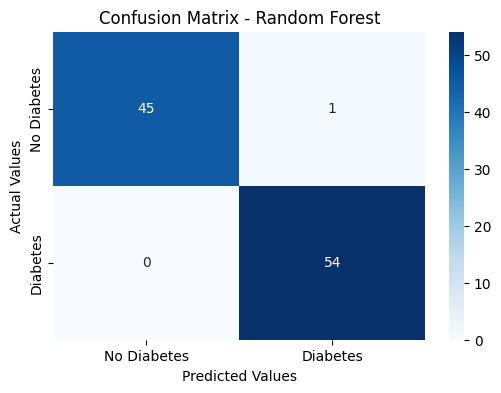

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Confusion Matrix - Random Forest')
plt.show()


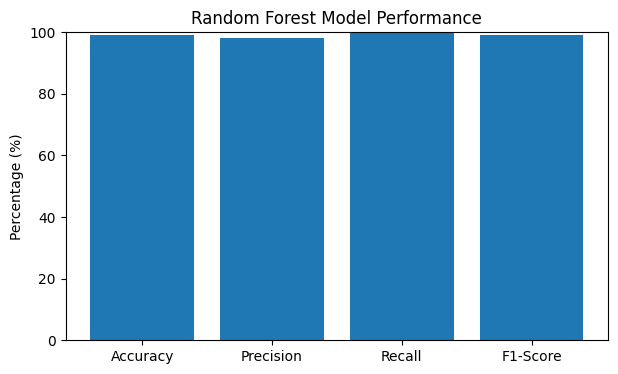

In [15]:

metrics = {
    'Accuracy': accuracy * 100,
    'Precision': precision * 100,
    'Recall': recall * 100,
    'F1-Score': f1 * 100
}

plt.figure(figsize=(7, 4))
plt.bar(metrics.keys(), metrics.values())
plt.ylabel('Percentage (%)')
plt.title('Random Forest Model Performance')
plt.ylim(0, 100)
plt.show()


In [16]:

results = pd.DataFrame({
    'Evaluation Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score (%)': [
        round(accuracy * 100, 2),
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(f1 * 100, 2)
    ]
})

print("FINAL MODEL EVALUATION")
display(results)


FINAL MODEL EVALUATION


,Evaluation Metric,Score (%)
0,Accuracy,99.00
1,Precision,98.18
2,Recall,100.00
3,F1-Score,99.08


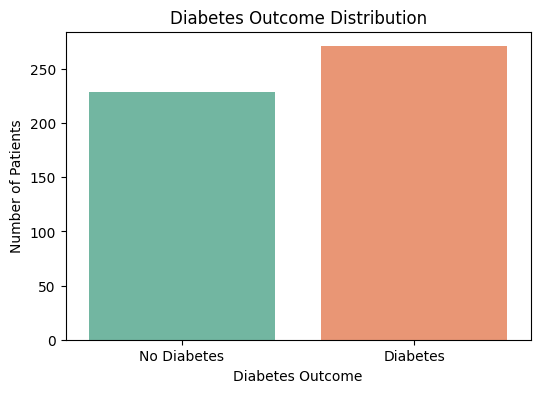

In [17]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='Diabetes_Outcome',
    hue='Diabetes_Outcome',
    palette='Set2',
    legend=False
)

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Number of Patients')
plt.xticks([0,1], ['No Diabetes', 'Diabetes'])
plt.show()

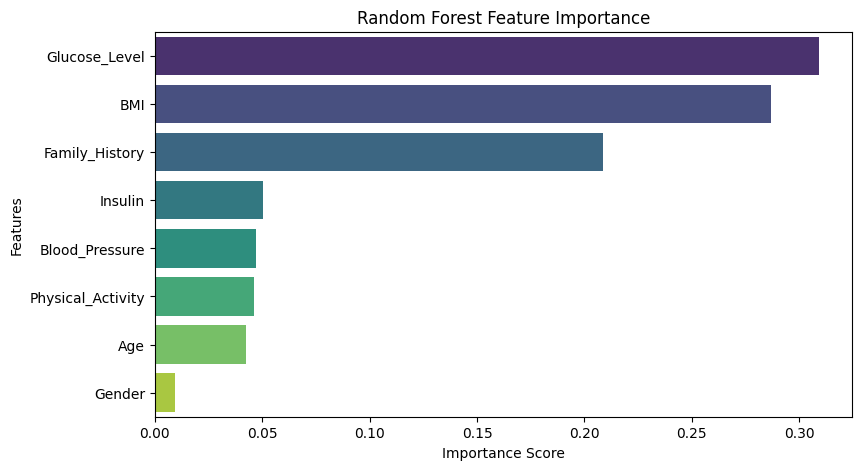

In [19]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

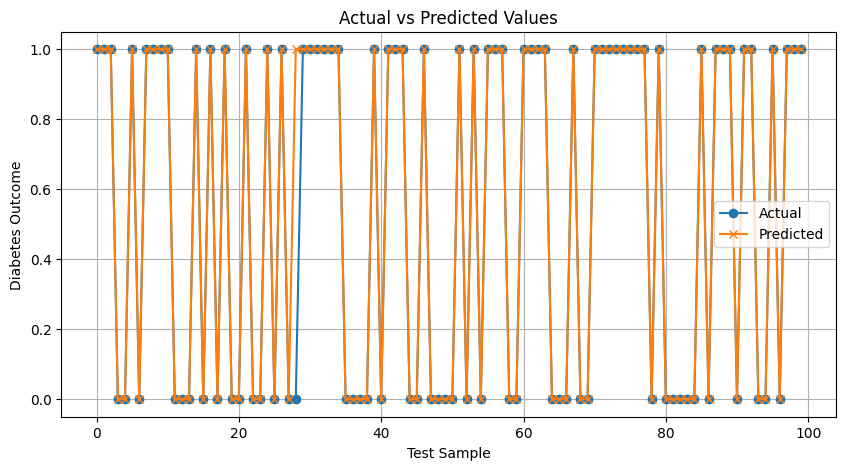

In [21]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison = comparison.reset_index(drop=True)

plt.figure(figsize=(10,5))

plt.plot(
    comparison.index,
    comparison['Actual'],
    label='Actual',
    marker='o'
)

plt.plot(
    comparison.index,
    comparison['Predicted'],
    label='Predicted',
    marker='x'
)

plt.xlabel('Test Sample')
plt.ylabel('Diabetes Outcome')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.grid()
plt.show()

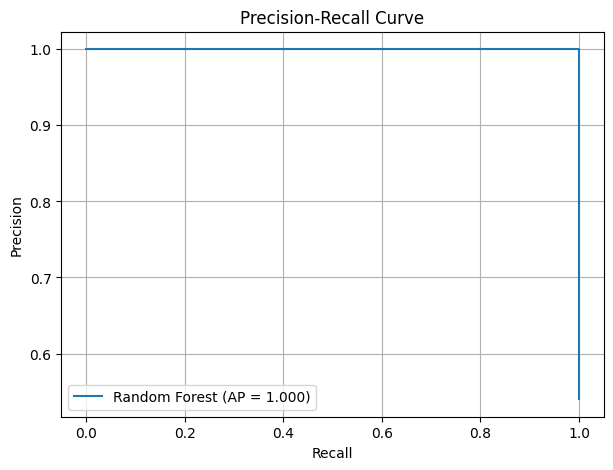

In [22]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_test, y_prob)
)

ap = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7,5))

plt.plot(
    recall_values,
    precision_values,
    label=f'Random Forest (AP = {ap:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid()
plt.show()